In this Discussion, we'll explore basic concepts and practical steps in text mining using Python.  
Text mining is a key technique in data science, natural language processing (NLP), and artificial intelligence.  
Let's get started!

## Why Do We Need to Do Text Mining?

Text mining refers to extracting meaningful information and patterns from unstructured text data.

**Why is text mining important?**
- The majority of the world's data is unstructured text (emails, social media, articles, etc.).
- Text mining helps us:
    - Summarize large volumes of information
    - Detect sentiment and opinions
    - Automatically categorize and cluster documents
    - Extract facts, keywords, and relationships
    - Support decision-making from text data

## Principles and Different Methods of Text Mining

Text mining involves several core steps and methods:

- **Text Preprocessing**: Cleaning and preparing raw text (removing punctuation, converting to lowercase, etc.)
- **Tokenization**: Splitting text into words or phrases
- **Stopword Removal**: Removing common words ("the", "is", "and") that add little value
- **Stemming/Lemmatization**: Reducing words to their root form (e.g., "running" → "run")
- **Vectorization**: Converting text to numerical format (e.g., Bag of Words, TF-IDF)
- **Analysis**:
    - **Classification**: Assigning categories to text (spam detection, sentiment analysis)
    - **Clustering**: Grouping similar documents
    - **Topic Modeling**: Identifying themes/topics in a corpus
    - **Information Extraction**: Pulling out entities, relationships, etc.

Text mining often uses Natural Language Processing (NLP) techniques.

## Basic Text Mining Packages and Examples

Let's try some basic text mining steps using Python packages.

We'll use:
- `nltk` (Natural Language Toolkit)
- `scikit-learn`
- `pandas`
- `matplotlib` (for visualization)

First, install the required packages if you haven't:

In [7]:
!pip install nltk scikit-learn pandas matplotlib

In [9]:
# Import packages
import pandas as pd
import nltk
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import matplotlib.pyplot as plt

# Download nltk resources
nltk.download('punkt')
nltk.download('stopwords')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Sample text data
texts = [
    "Text mining is fun and useful!",
    "Natural Language Processing is a key part of AI.",
    "Python makes text mining easy.",
    "We analyze text to gain insights.",
]

df = pd.DataFrame({'text': texts})
df

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Jennifer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Jennifer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,text
0,Text mining is fun and useful!
1,Natural Language Processing is a key part of AI.
2,Python makes text mining easy.
3,We analyze text to gain insights.


In [4]:
# Text preprocessing: lowercasing, tokenization, stopword removal

def preprocess(text):
    # Lowercase all words to decrease error caused by capitalization
    text = text.lower()
    # Tokenize
    tokens = word_tokenize(text)
    # Remove stopwords that do not have sufficient meaning (eg: is, and, to)
    stop_words = set(stopwords.words('english'))
    tokens = [w for w in tokens if w.isalpha() and w not in stop_words]
    return tokens

df['tokens'] = df['text'].apply(preprocess)
df

,text,tokens
0,Text mining is fun and useful!,"[text, mining, fun, useful]"
1,Natural Language Processing is a key part of AI.,"[natural, language, processing, key, part, ai]"
2,Python makes text mining easy.,"[python, makes, text, mining, easy]"
3,We analyze text to gain insights.,"[analyze, text, gain, insights]"


### Vectorization

Machine learning algorithms and statistical models require **numerical input**.  
Raw text is unstructured and cannot be directly used in these models.

**Vectorization** transforms text into numerical vectors, so we can:
- Measure similarity between documents
- Train machine learning models (classification, clustering, etc.)
- Visualize text data

Common methods:
- **Bag of Words (BoW):** Counts word occurrences.
- **TF-IDF:** Weighs words by how important they are in a document relative to the corpus.

In [5]:
# Vectorization: Bag of Words

vectorizer = CountVectorizer(stop_words='english')
X = vectorizer.fit_transform(df['text'])

bow_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
bow_df

,ai,analyze,easy,fun,gain,insights,key,language,makes,mining,natural,processing,python,text,useful
0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,1
1,1,0,0,0,0,0,1,1,0,0,1,1,0,0,0
2,0,0,1,0,0,0,0,0,1,1,0,0,1,1,0
3,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0


In [6]:
# Vectorization: TF-IDF (Term Frequency-Inverse Document Frequency)
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
X_tfidf = tfidf_vectorizer.fit_transform(df['text'])

tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
tfidf_df

,ai,analyze,easy,fun,gain,insights,key,language,makes,mining,natural,processing,python,text,useful
0,0.000000,0.000000,0.000000,0.57458,0.000000,0.000000,0.000000,0.000000,0.000000,0.453005,0.000000,0.000000,0.000000,0.366747,0.57458
1,0.447214,0.000000,0.000000,0.00000,0.000000,0.000000,0.447214,0.447214,0.000000,0.000000,0.447214,0.447214,0.000000,0.000000,0.00000
2,0.000000,0.000000,0.498197,0.00000,0.000000,0.000000,0.000000,0.000000,0.498197,0.392784,0.000000,0.000000,0.498197,0.317993,0.00000
3,0.000000,0.541736,0.000000,0.00000,0.541736,0.541736,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.345783,0.00000


### How To Utilize and Visualize Vectorization Results

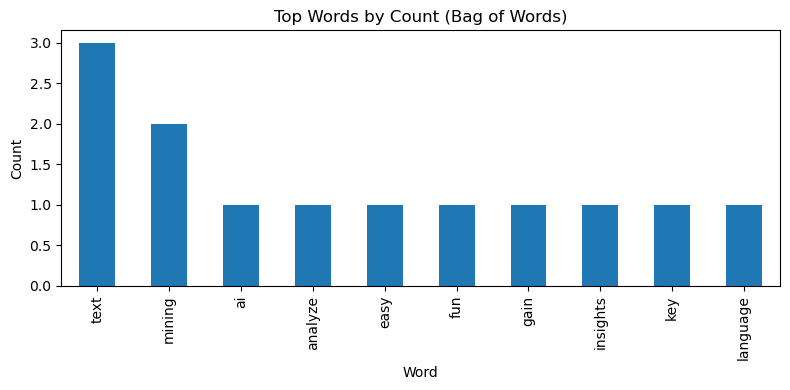

In [10]:
# Visualize top words by total count (Bag of Words)
bow_sum = bow_df.sum().sort_values(ascending=False)

plt.figure(figsize=(8,4))
bow_sum.head(10).plot(kind='bar')
plt.title('Top Words by Count (Bag of Words)')
plt.ylabel('Count')
plt.xlabel('Word')
plt.tight_layout()
plt.show()

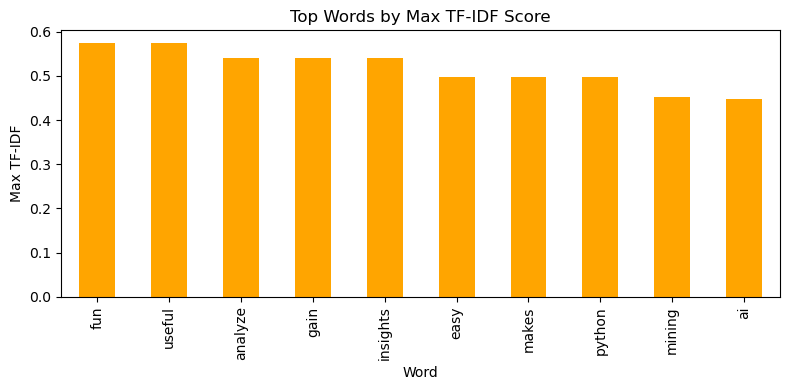

In [11]:
# Visualize top words by max TF-IDF score
tfidf_max = tfidf_df.max().sort_values(ascending=False)

plt.figure(figsize=(8,4))
tfidf_max.head(10).plot(kind='bar', color='orange')
plt.title('Top Words by Max TF-IDF Score')
plt.ylabel('Max TF-IDF')
plt.xlabel('Word')
plt.tight_layout()
plt.show()

## Practice Exercises: Try Text Mining Yourself!


Now it's your turn!  
Try these exercises to apply what you've learned about text mining.

### Exercise 1: Preprocess Your Own Text
- Write a sentence or short paragraph of your choice.
- Tokenize it, remove stopwords, and print the cleaned tokens.

### Exercise 2: Vectorize a New Set of Sentences
- Create a new list of 3–5 sentences on any topic.
- Use `CountVectorizer` and `TfidfVectorizer` to transform them.
- Display the resulting DataFrames.

### Exercise 3: Visualize Word Frequencies
- Using the Bag of Words results from Exercise 2, plot a bar chart of the top 5 words.

### Exercise 4: Bonus—Compare Two Sentences
- Pick any two sentences.
- Preprocess and vectorize them.
- Compute and print the cosine similarity between their TF-IDF vectors using `sklearn.metrics.pairwise.cosine_similarity`.

---

Feel free to add more sentences, try different topics, or modify the code!  
Exploring text data with your own examples is a great way to learn.

**Challenge:**  
Can you find the most "important" word in your own mini-corpus using TF-IDF?

---